<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Missing values before cleaning: 87
Missing values after cleaning : 0

X_train shape: (6984, 24, 1), y_train shape: (6984, 1)
X_test  shape: (1728, 24, 1),  y_test  shape: (1728, 1)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0211 - val_loss: 0.0023
Epoch 2/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0015 - val_loss: 0.0018
Epoch 3/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0014 - val_loss: 0.0018
Epoch 4/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013 - val_loss: 0.0019
Epoch 5/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0013 - val_loss: 0.0019
Epoch 6/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0013 - val_loss: 0.0019
Epoch 7/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0013 - val_loss: 0.0018
Epoch 8/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012 - val_loss: 0.0017
Epoch 9/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012 - val_loss: 0.0015
Epoch 10/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012 - val_loss: 0.0014
Epoch 11/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012 - val_loss: 0.0014
Epoch 12/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012 - val

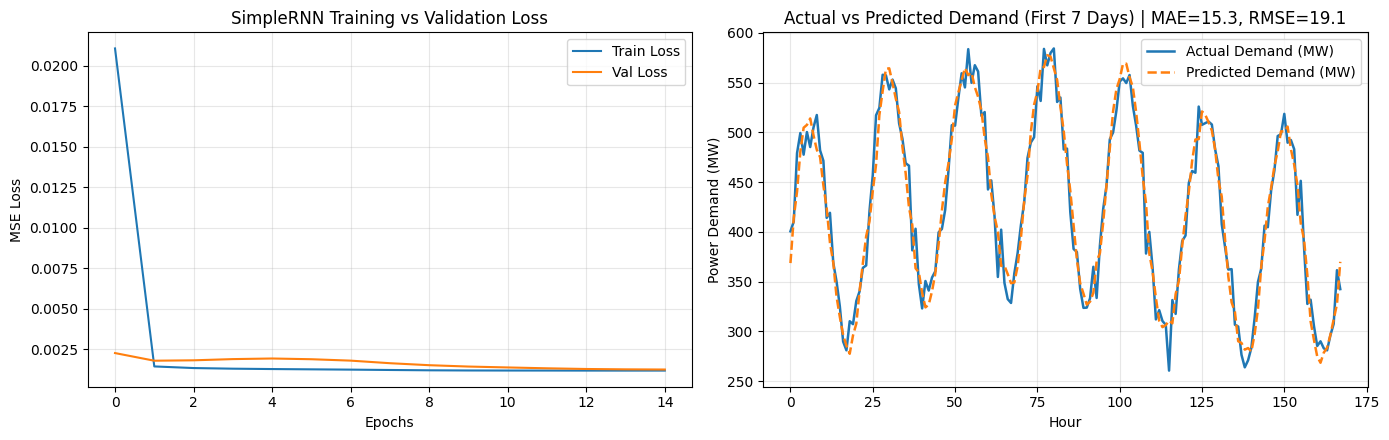

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Task 1: Load Series, Handle Missing Values & Scale
# ==========================================
# Generate 1 year (8,760 hours) of synthetic hourly electricity demand (MW)
hours = pd.date_range(start="2025-01-01", periods=365 * 24, freq="h")
t = np.arange(len(hours))

demand = (
    500
    + 120 * np.sin(2 * np.pi * t / 24)           # Daily cycle
    + 40 * np.sin(2 * np.pi * t / (24 * 7))      # Weekly cycle
    + 80 * np.sin(2 * np.pi * t / (24 * 365))    # Seasonal cycle
    + np.random.normal(0, 15, len(hours))        # Random noise
)

df = pd.DataFrame({"timestamp": hours, "demand_mw": demand})

# Inject 1% missing values to demonstrate handling
missing_idx = np.random.choice(len(df), size=int(0.01 * len(df)), replace=False)
df.loc[missing_idx, "demand_mw"] = np.nan

print(f"Missing values before cleaning: {df['demand_mw'].isna().sum()}")
df["demand_mw"] = df["demand_mw"].interpolate(method="linear").bfill().ffill()
print(f"Missing values after cleaning : {df['demand_mw'].isna().sum()}\n")

# Chronological split index (80% train, 20% test) before fitting scaler to avoid leakage
split_idx = int(len(df) * 0.8)
scaler = MinMaxScaler(feature_range=(0, 1))

train_raw = df[["demand_mw"]].iloc[:split_idx].values
test_raw = df[["demand_mw"]].iloc[split_idx:].values

train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)

# ==========================================
# Task 2 & 3: Sliding Windows (24h -> Next Hour) & Chronological Split
# ==========================================
WINDOW_SIZE = 24

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i : i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, WINDOW_SIZE)
X_test, y_test = create_sequences(test_scaled, WINDOW_SIZE)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test  shape: {X_test.shape},  y_test  shape: {y_test.shape}\n")

# ==========================================
# Task 4: Build and Train SimpleRNN Model in Keras
# ==========================================
model = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 1)),
    layers.SimpleRNN(32, activation="tanh"),
    layers.Dense(1)
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
model.summary()

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=64,
    verbose=1
)

# ==========================================
# Task 5: Plot Actual vs Predicted & Report MAE / RMSE
# ==========================================
y_pred_scaled = model.predict(X_test, verbose=0)

# Inverse transform back to MW
y_test_mw = scaler.inverse_transform(y_test)
y_pred_mw = scaler.inverse_transform(y_pred_scaled)

mae = mean_absolute_error(y_test_mw, y_pred_mw)
rmse = np.sqrt(mean_squared_error(y_test_mw, y_pred_mw))

print(f"\n=== Test Set Performance (Next-Hour Power Demand) ===")
print(f"MAE : {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Training vs Validation Loss
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("SimpleRNN Training vs Validation Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("MSE Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Actual vs Predicted (First 7 days = 168 hours of test set for clear visibility)
n_plot = 168
axes[1].plot(y_test_mw[:n_plot], label="Actual Demand (MW)", linewidth=1.8)
axes[1].plot(y_pred_mw[:n_plot], label="Predicted Demand (MW)", linestyle="--", linewidth=1.8)
axes[1].set_title(f"Actual vs Predicted Demand (First 7 Days) | MAE={mae:.1f}, RMSE={rmse:.1f}")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Power Demand (MW)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()